# Physics-Informed Neural Network for the Swing Equation

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/enliten/IEEE-course_AI-for-Power-Energy-Systems/blob/main/PINN_Frequency.ipynb)

**Contact:** Buxin She ([shebuxin@gmail.com](mailto:shebuxin@gmail.com))  

This notebook introduces a **Physics-Informed Neural Network (PINN)** through a small power-system swing-equation example. The model learns the rotor-angle deviation and angular speed deviation after a small disturbance. Frequency deviation in hertz is obtained from the angular speed deviation as $\Delta f=\omega/(2\pi)$.

The goal is to show beginners how a neural network can use both sparse data and physical equations in a fully verifiable setting.

## Table of Contents

0. [Setup](#step-0-setup)
1. [Problem Statement](#step-1-problem-statement)
2. [Governing Physics](#step-2-governing-physics)
3. [Generate Reference Solution](#step-3-generate-reference-solution)
4. [Create Sparse Measurement Data](#step-4-create-sparse-measurement-data)
5. [Ordinary Neural Network Baseline](#step-5-ordinary-neural-network-baseline)
6. [Define the PINN Model](#step-6-define-the-pinn-model)
7. [Define PINN Loss](#step-7-define-pinn-loss)
8. [Train the PINN](#step-8-train-the-pinn)
9. [Evaluate and Compare](#step-9-evaluate-and-compare)
10. [References](#references)


## Step 0. Setup

We use NumPy for the analytical reference solution, PyTorch for the neural networks and automatic differentiation, and Matplotlib for visualization. These packages are included in the standard Google Colab Python runtime, so no installation cell or local file is required. Select **Runtime > Run all**; the notebook intentionally uses the CPU for reproducible behavior across Colab hardware.


In [1]:
# Step 0. Setup
import copy
import random
import warnings

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)

device = torch.device("cpu")
print("Setup complete. PyTorch version:", torch.__version__)
print("Using device:", device)

learning_goal = {
    "input": "time t after a small disturbance",
    "outputs": "rotor-angle deviation delta(t) and angular-speed deviation omega(t)",
    "data": "nine sparse synthetic state samples of delta(t) and omega(t)",
    "physics": "linearized swing equation with synchronizing power coefficient Ks",
    "comparison": "ordinary NN vs PINN",
}

for key, value in learning_goal.items():
    print(f"{key:>10}: {value}")


Setup complete. PyTorch version: 2.12.1
Using device: cpu
     input: time t after a small disturbance
   outputs: rotor-angle deviation delta(t) and angular-speed deviation omega(t)
      data: nine sparse synthetic state samples of delta(t) and omega(t)
   physics: linearized swing equation with synchronizing power coefficient Ks
comparison: ordinary NN vs PINN


## Step 1. Problem Statement

For a small electromechanical mode represented relative to a synchronous reference, the equivalent rotor angle does not return to a new operating point instantly after a small power imbalance. It can swing around the new equilibrium, and the oscillation gradually decays if damping is present.

We compare two neural-network approaches:

- **ordinary neural network**: trained with the same two-output architecture, the same sparse synthetic rotor-angle and angular-speed samples, and the same initial condition;
- **PINN**: trained with the same sparse state samples and initial condition, plus the governing swing-equation residuals.

The key idea is that the residual-free ordinary neural network is asked only to fit the sparse state samples and satisfy the initial state. The PINN is trained on the same targets and is additionally penalized for violating the known electromechanical equations between those points.


In [2]:
problem_summary = {
    "state_1": "delta(t): rotor angle deviation",
    "state_2": "omega(t): angular-speed deviation in rad/s, equal to d delta / dt",
    "disturbance": "constant small power imbalance Delta P",
    "expected_shape": "underdamped oscillation with decaying amplitude",
}

for key, value in problem_summary.items():
    print(f"{key:>12}: {value}")

     state_1: delta(t): rotor angle deviation
     state_2: omega(t): angular-speed deviation in rad/s, equal to d delta / dt
 disturbance: constant small power imbalance Delta P
expected_shape: underdamped oscillation with decaying amplitude


## Step 2. Governing Physics

For this introductory PINN demo, we use an equivalent two-state linearized swing-equation model relative to a synchronous reference:

$$
\frac{d\delta}{dt}=\omega,
$$

$$
M\frac{d\omega}{dt} = \Delta P - D\omega - K_s\delta.
$$

Symbol meanings:

- $t$ is time in seconds;
- $\delta(t)$ is the small electrical rotor-angle deviation in radians;
- $\omega(t)=d\delta/dt$ is the angular-speed deviation in rad/s; the corresponding frequency deviation is $\Delta f=\omega/(2\pi)$ in hertz;
- $M$ is an equivalent inertia coefficient in $\mathrm{pu}\cdot\mathrm{s}^2/\mathrm{rad}$, with $M>0$;
- $D$ is a damping coefficient in $\mathrm{pu}\cdot\mathrm{s}/\mathrm{rad}$, with $D>0$;
- $K_s$ is the synchronizing-power coefficient in pu/rad, with $K_s>0$ from the linearized power-angle relationship;
- $\Delta P$ is a constant small power imbalance in per unit. With the sign convention used here, $\Delta P>0$ gives a positive initial angular acceleration.

This compact single-machine-equivalent model is the physical constraint used later in the PINN residual. The units above make every term in the second equation a per-unit power quantity.


In [3]:
# Step 2. Physical parameters for the linearized swing-equation model.
M = 2.0          # pu*s^2/rad: equivalent inertia coefficient
D = 1.0          # pu*s/rad: damping coefficient
Ks = 2.0         # pu/rad: synchronizing-power coefficient
delta_p = 0.20   # pu: constant small power imbalance
T_END = 20.0     # s

omega_n = np.sqrt(Ks / M)
damping_ratio = D / (2.0 * np.sqrt(M * Ks))
omega_d = omega_n * np.sqrt(1.0 - damping_ratio**2)
delta_ss = delta_p / Ks

# Characteristic physical scales used to form dimensionless training losses.
DELTA_SCALE = max(abs(delta_ss), 1e-6)              # rad
OMEGA_SCALE = max(omega_n * DELTA_SCALE, 1e-6)     # rad/s
R_DELTA_SCALE = OMEGA_SCALE                         # rad/s
R_OMEGA_SCALE = max(abs(delta_p), 1e-6)             # pu

print(f"M = {M} pu*s^2/rad")
print(f"D = {D} pu*s/rad")
print(f"Ks = {Ks} pu/rad")
print(f"Delta P = {delta_p} pu")
print(f"Natural frequency omega_n = {omega_n:.4f} rad/s")
print(f"Damping ratio zeta = {damping_ratio:.4f}")
print(f"Damped frequency omega_d = {omega_d:.4f} rad/s")
print(f"Steady-state rotor angle delta_ss = Delta P / Ks = {delta_ss:.4f} rad")
print(f"Loss scales: delta={DELTA_SCALE:.4f} rad, omega={OMEGA_SCALE:.4f} rad/s, "
      f"r_delta={R_DELTA_SCALE:.4f} rad/s, r_omega={R_OMEGA_SCALE:.4f} pu")


M = 2.0 pu*s^2/rad
D = 1.0 pu*s/rad
Ks = 2.0 pu/rad
Delta P = 0.2 pu
Natural frequency omega_n = 1.0000 rad/s
Damping ratio zeta = 0.2500
Damped frequency omega_d = 0.9682 rad/s
Steady-state rotor angle delta_ss = Delta P / Ks = 0.1000 rad
Loss scales: delta=0.1000 rad, omega=0.1000 rad/s, r_delta=0.1000 rad/s, r_omega=0.2000 pu


## Step 3. Generate Reference Solution

Because this linearized second-order model has a known analytical solution, we can generate a reference curve. This is useful for verification.


Max finite-difference delta residual (interior): 2.170370438051017e-05
Max analytical swing residual: 5.551115123125783e-17


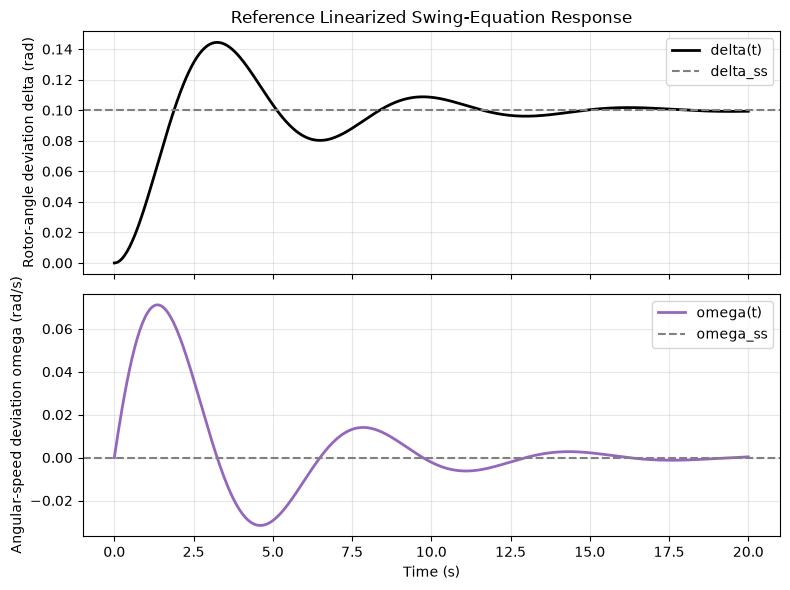

In [4]:
def swing_response_exact(t, M, D, Ks, delta_p):
    """Analytical underdamped step response of M delta_ddot + D delta_dot + Ks delta = delta_p."""
    t_array = np.asarray(t, dtype=float)
    flat_t = t_array.reshape(-1)

    omega_n = np.sqrt(Ks / M)
    zeta = D / (2.0 * np.sqrt(M * Ks))
    if not (0.0 < zeta < 1.0):
        raise ValueError("This teaching function expects an underdamped case with 0 < zeta < 1.")

    omega_d = omega_n * np.sqrt(1.0 - zeta**2)
    alpha = zeta * omega_n
    delta_ss = delta_p / Ks

    exp_term = np.exp(-alpha * flat_t)
    sin_term = np.sin(omega_d * flat_t)
    cos_term = np.cos(omega_d * flat_t)

    delta = delta_ss * (1.0 - exp_term * (cos_term + (alpha / omega_d) * sin_term))
    omega = delta_ss * (omega_n**2 / omega_d) * exp_term * sin_term

    return delta.reshape(t_array.shape), omega.reshape(t_array.shape)


t_eval_np = np.linspace(0.0, T_END, 500).reshape(-1, 1)
delta_exact_np, omega_exact_np = swing_response_exact(t_eval_np, M, D, Ks, delta_p)

# Verify d(delta)/dt independently with a centered finite difference.
t_eval_flat = t_eval_np.reshape(-1)
ddelta_numeric_dt_np = np.gradient(
    delta_exact_np.reshape(-1), t_eval_flat, edge_order=2
).reshape(-1, 1)
alpha = damping_ratio * omega_n
domega_exact_dt_np = (
    delta_ss
    * (omega_n**2 / omega_d)
    * np.exp(-alpha * t_eval_np)
    * (omega_d * np.cos(omega_d * t_eval_np) - alpha * np.sin(omega_d * t_eval_np))
)
r_delta_exact_np = ddelta_numeric_dt_np - omega_exact_np
r_omega_exact_np = M * domega_exact_dt_np + D * omega_exact_np + Ks * delta_exact_np - delta_p
interior = slice(2, -2)  # avoid one-sided finite-difference endpoints
print("Max finite-difference delta residual (interior):",
      float(np.max(np.abs(r_delta_exact_np[interior]))))
print("Max analytical swing residual:", float(np.max(np.abs(r_omega_exact_np))))

fig, axes = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
axes[0].plot(t_eval_np, delta_exact_np, color="black", linewidth=2, label="delta(t)")
axes[0].axhline(delta_ss, linestyle="--", color="gray", label="delta_ss")
axes[0].set_ylabel("Rotor-angle deviation delta (rad)")
axes[0].set_title("Reference Linearized Swing-Equation Response")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(t_eval_np, omega_exact_np, color="tab:purple", linewidth=2, label="omega(t)")
axes[1].axhline(0.0, linestyle="--", color="gray", label="omega_ss")
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Angular-speed deviation omega (rad/s)")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()


## Step 4. Create Sparse Measurement Data

To show why physics information helps, we create nine synthetic measurement-like state samples from the analytical solution. These samples are not field measurements; they are noiseless reference values for an introductory, fully verifiable demo. The sample times exclude $t=0$ because the initial condition is supplied separately.

Both $\delta(t)$ and angular-speed $\omega(t)$ samples are used as labeled data for the ordinary neural network and for the PINN. This avoids an underconstrained angular-speed output in the ordinary baseline. The PINN then receives the same sparse state labels plus the swing-equation residual.


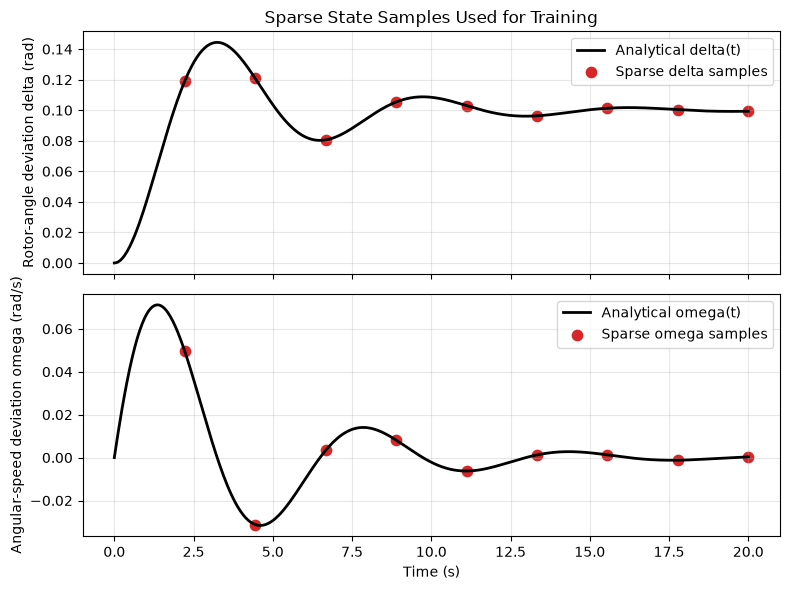

In [5]:
# Step 4. Sparse synthetic state samples
# Nine non-initial points keep the data sparse; t=0 is enforced only through the IC loss.
measurement_times = np.linspace(T_END / 9.0, T_END, 9).reshape(-1, 1)
measurement_delta, measurement_omega = swing_response_exact(measurement_times, M, D, Ks, delta_p)

# Torch tensors used for training
t_data = torch.tensor(measurement_times, dtype=torch.float32, device=device)
delta_data = torch.tensor(measurement_delta, dtype=torch.float32, device=device)
omega_data = torch.tensor(measurement_omega, dtype=torch.float32, device=device)
state_data = torch.cat([delta_data, omega_data], dim=1)
t_eval = torch.tensor(t_eval_np, dtype=torch.float32, device=device)
delta_exact = torch.tensor(delta_exact_np, dtype=torch.float32, device=device)
omega_exact = torch.tensor(omega_exact_np, dtype=torch.float32, device=device)

fig, axes = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
axes[0].plot(t_eval_np, delta_exact_np, color="black", linewidth=2, label="Analytical delta(t)")
axes[0].scatter(measurement_times, measurement_delta, color="tab:red", s=55, label="Sparse delta samples")
axes[0].set_ylabel("Rotor-angle deviation delta (rad)")
axes[0].set_title("Sparse State Samples Used for Training")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(t_eval_np, omega_exact_np, color="black", linewidth=2, label="Analytical omega(t)")
axes[1].scatter(measurement_times, measurement_omega, color="tab:red", s=55, label="Sparse omega samples")
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Angular-speed deviation omega (rad/s)")
axes[1].grid(True, alpha=0.3)
axes[1].legend()
plt.tight_layout()
plt.show()


## Step 5. Ordinary Neural Network Baseline

First, we train a small ordinary neural network with the same two-output architecture used by the PINN:

$$
[\hat{\delta}(t), \hat{\omega}(t)].
$$

For data fairness, this ordinary neural network uses the same sparse synthetic rotor-angle and angular-speed samples as the PINN, together with the initial condition $\delta(0)=0,\omega(0)=0$. Angular-speed samples are used as training labels; without an $\omega$ term, that output would be almost unconstrained.

For a controlled comparison, the ordinary NN and PINN start from identical weights and receive the same Adam and L-BFGS optimization budgets. Their state and residual errors are divided by declared physical scales before the loss terms are combined.

In this simple fixed-disturbance demo, the neural-network input is the time variable $t$, not the rotor angle. The outputs are the state estimates $\hat{\delta}(t)$ and $\hat{\omega}(t)$. This follows the usual PINN viewpoint. The network approximates the solution of a differential equation as a function of its independent variable. More realistic power-system PINN or surrogate-model versions usually use time together with input variables, such as disturbance level, control signal, or model parameters.


Ordinary NN after L-BFGS | total=2.828e-02 | data=2.827e-02 | ic=2.313e-07
Ordinary NN delta MAE against analytical solution: 0.010591
Ordinary NN omega MAE against analytical solution: 0.010708


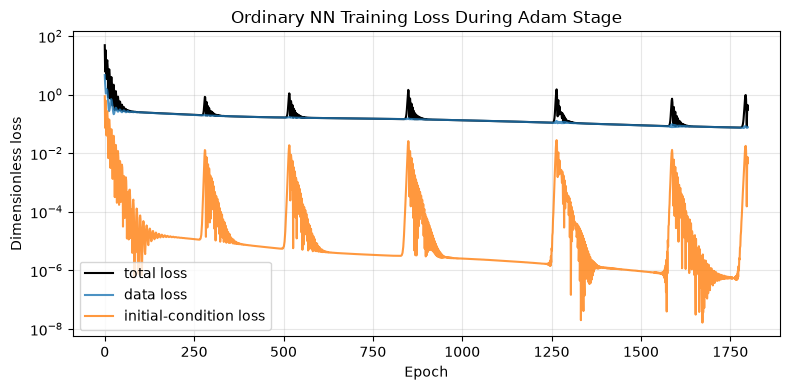

In [6]:
class MLP(nn.Module):
    """Small fully connected network mapping time t to one or more state variables."""

    def __init__(self, output_dim=2, hidden=64, t_end=T_END):
        super().__init__()
        self.t_end = float(t_end)
        self.net = nn.Sequential(
            nn.Linear(1, hidden),
            nn.Tanh(),
            nn.Linear(hidden, hidden),
            nn.Tanh(),
            nn.Linear(hidden, hidden),
            nn.Tanh(),
            nn.Linear(hidden, output_dim),
        )

    def forward(self, t):
        tau = 2.0 * t / self.t_end - 1.0
        return self.net(tau)


mse = nn.MSELoss()
ADAM_EPOCHS = 1800
ADAM_LR = 1e-3
LBFGS_STEPS = 200
LBFGS_LR = 0.8
LAMBDA_IC = 50.0

t_initial = torch.zeros((1, 1), dtype=torch.float32, device=device)
initial_state = torch.zeros((1, 2), dtype=torch.float32, device=device)

def scaled_state_loss(prediction, target):
    """Dimensionless sum of the delta and omega mean-square errors."""
    delta_error = (prediction[:, 0:1] - target[:, 0:1]) / DELTA_SCALE
    omega_error = (prediction[:, 1:2] - target[:, 1:2]) / OMEGA_SCALE
    return mse(delta_error, torch.zeros_like(delta_error)) + mse(
        omega_error, torch.zeros_like(omega_error)
    )


def compute_data_only_losses(model):
    data_loss = scaled_state_loss(model(t_data), state_data)
    ic_loss = scaled_state_loss(model(t_initial), initial_state)
    return data_loss + LAMBDA_IC * ic_loss, data_loss, ic_loss


def train_data_only_model(model):
    optimizer = optim.Adam(model.parameters(), lr=ADAM_LR)
    history = {"total_loss": [], "data_loss": [], "ic_loss": []}

    for _ in range(ADAM_EPOCHS):
        total_loss, data_loss, ic_loss = compute_data_only_losses(model)
        optimizer.zero_grad()
        total_loss.backward()
        optimizer.step()
        history["total_loss"].append(float(total_loss.item()))
        history["data_loss"].append(float(data_loss.item()))
        history["ic_loss"].append(float(ic_loss.item()))

    lbfgs = optim.LBFGS(
        model.parameters(), lr=LBFGS_LR, max_iter=LBFGS_STEPS,
        max_eval=LBFGS_STEPS, tolerance_grad=1e-9,
        tolerance_change=1e-11, line_search_fn="strong_wolfe",
    )

    def closure():
        total_loss, _, _ = compute_data_only_losses(model)
        lbfgs.zero_grad()
        total_loss.backward()
        return total_loss

    lbfgs.step(closure)
    total_loss, data_loss, ic_loss = compute_data_only_losses(model)
    print(
        f"Ordinary NN after L-BFGS | total={total_loss.item():.3e} | "
        f"data={data_loss.item():.3e} | ic={ic_loss.item():.3e}"
    )
    return history


# Both models start from exactly the same parameters.
initial_model = MLP(output_dim=2).to(device)
shared_initial_state_dict = copy.deepcopy(initial_model.state_dict())
data_model = MLP(output_dim=2).to(device)
data_model.load_state_dict(shared_initial_state_dict)
data_only_history = train_data_only_model(data_model)

with torch.no_grad():
    data_only_pred = data_model(t_eval)
    data_only_delta_pred = data_only_pred[:, 0:1]
    data_only_omega_pred = data_only_pred[:, 1:2]
    data_only_delta_mae = torch.mean(torch.abs(data_only_delta_pred - delta_exact)).item()
    data_only_omega_mae = torch.mean(torch.abs(data_only_omega_pred - omega_exact)).item()

print(f"Ordinary NN delta MAE against analytical solution: {data_only_delta_mae:.6f}")
print(f"Ordinary NN omega MAE against analytical solution: {data_only_omega_mae:.6f}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.semilogy(data_only_history["total_loss"], label="total loss", color="black")
ax.semilogy(data_only_history["data_loss"], label="data loss", alpha=0.8)
ax.semilogy(data_only_history["ic_loss"], label="initial-condition loss", alpha=0.8)
ax.set_xlabel("Epoch")
ax.set_ylabel("Dimensionless loss")
ax.set_title("Ordinary NN Training Loss During Adam Stage")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()


## Step 6. Define the PINN Model

The PINN uses the same architecture, identical initial weights, and the same Adam plus L-BFGS optimization budget as the ordinary baseline. In this controlled fixed-seed comparison, the intended difference is the dimensionless swing-equation residual term computed with automatic differentiation.


In [7]:
pinn_model = MLP(output_dim=2).to(device)
pinn_model.load_state_dict(shared_initial_state_dict)
print(pinn_model)

MLP(
  (net): Sequential(
    (0): Linear(in_features=1, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): Tanh()
    (4): Linear(in_features=64, out_features=64, bias=True)
    (5): Tanh()
    (6): Linear(in_features=64, out_features=2, bias=True)
  )
)


## Step 7. Define PINN Loss

For neural-network predictions $\hat{\delta}(t)$ and $\hat{\omega}(t)$, the two physics residuals are

$$
r_{\delta}(t)=\frac{d\hat{\delta}}{dt}-\hat{\omega},
$$

$$
r_{\omega}(t)=M\frac{d\hat{\omega}}{dt}+D\hat{\omega}+K_s\hat{\delta}-\Delta P.
$$

Before combining quantities with different engineering units, we divide them by declared characteristic scales $s_\delta$, $s_\omega$, $s_{r_\delta}$, and $s_{r_\omega}$. All loss terms below are therefore dimensionless. Define

$$
e_\delta=\frac{\hat\delta-\delta}{s_\delta},\qquad e_\omega=\frac{\hat\omega-\omega}{s_\omega},\qquad \bar r_\delta=\frac{r_\delta}{s_{r_\delta}},\qquad \bar r_\omega=\frac{r_\omega}{s_{r_\omega}}.
$$

$$
\mathcal{L}_{data}=\text{MSE}(e_\delta,0)+\text{MSE}(e_\omega,0),
$$

$$
\mathcal{L}_{physics}=\text{MSE}(\bar r_{\delta},0)+\text{MSE}(\bar r_{\omega},0),
$$

$$
\mathcal{L}_{IC}=\text{MSE}(\hat{\delta}(0)/s_\delta,0)+\text{MSE}(\hat{\omega}(0)/s_\omega,0).
$$

The total dimensionless loss is

$$
\mathcal{L}=\mathcal{L}_{data}+\lambda_{physics}\mathcal{L}_{physics}+\lambda_{IC}\mathcal{L}_{IC}.
$$


In [8]:
def physics_residual(model, t_collocation, M, D, Ks, delta_p):
    """Compute swing-equation residuals using PyTorch autograd."""
    t_for_grad = t_collocation.clone().detach().requires_grad_(True)
    prediction = model(t_for_grad)
    delta_hat = prediction[:, 0:1]
    omega_hat = prediction[:, 1:2]

    d_delta_dt = torch.autograd.grad(
        delta_hat,
        t_for_grad,
        grad_outputs=torch.ones_like(delta_hat),
        create_graph=True,
    )[0]
    d_omega_dt = torch.autograd.grad(
        omega_hat,
        t_for_grad,
        grad_outputs=torch.ones_like(omega_hat),
        create_graph=True,
    )[0]

    r_delta = d_delta_dt - omega_hat
    r_omega = M * d_omega_dt + D * omega_hat + Ks * delta_hat - delta_p
    return r_delta, r_omega


LAMBDA_PHYSICS = 50.0

t_collocation = torch.linspace(0.0, T_END, 300, device=device).reshape(-1, 1)

# Check residual shapes before training.
initial_r_delta, initial_r_omega = physics_residual(pinn_model, t_collocation, M, D, Ks, delta_p)
print("r_delta tensor shape:", tuple(initial_r_delta.shape))
print("r_omega tensor shape:", tuple(initial_r_omega.shape))


r_delta tensor shape: (300, 1)
r_omega tensor shape: (300, 1)


## Step 8. Train the PINN

The PINN sees the same sparse state samples and the same initial condition as the ordinary neural network, plus collocation points where the swing-equation residuals are evaluated. These collocation points do not require measured labels.

Both models use the same number of Adam epochs followed by the same maximum number of L-BFGS iterations. This controls the initialization and optimizer budget; the result remains a fixed-seed teaching comparison rather than a universal guarantee that every PINN will outperform every ordinary neural network.


Adam epoch  500 | total=3.009e+00 | data=1.283e-01 | physics=5.258e-02 | ic=5.027e-03


Adam epoch 1000 | total=1.254e+00 | data=7.033e-02 | physics=2.212e-02 | ic=1.547e-03


Adam epoch 1500 | total=6.025e-01 | data=3.200e-02 | physics=1.114e-02 | ic=2.720e-04


After L-BFGS | total=3.526e-02 | data=4.761e-03 | physics=6.092e-04 | ic=8.778e-07
PINN training finished.


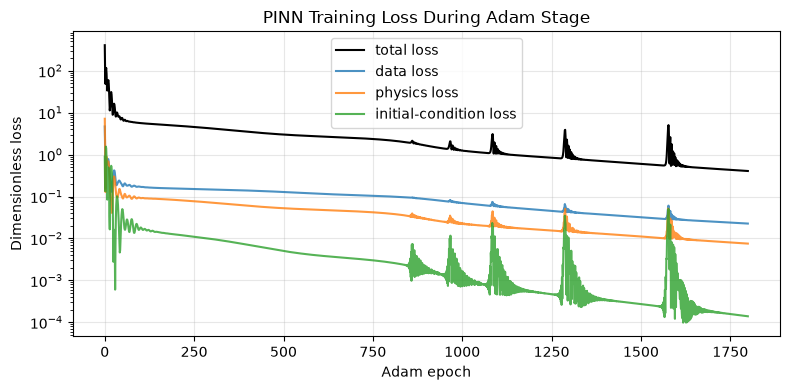

In [9]:
def compute_pinn_losses(model):
    pred_data = model(t_data)
    data_loss = scaled_state_loss(pred_data, state_data)

    r_delta, r_omega = physics_residual(model, t_collocation, M, D, Ks, delta_p)
    r_delta_scaled = r_delta / R_DELTA_SCALE
    r_omega_scaled = r_omega / R_OMEGA_SCALE
    physics_loss = mse(r_delta_scaled, torch.zeros_like(r_delta_scaled)) + mse(
        r_omega_scaled, torch.zeros_like(r_omega_scaled)
    )

    pred_initial = model(t_initial)
    ic_loss = scaled_state_loss(pred_initial, initial_state)

    total_loss = data_loss + LAMBDA_PHYSICS * physics_loss + LAMBDA_IC * ic_loss
    return total_loss, data_loss, physics_loss, ic_loss


def train_pinn_model(model):
    adam = optim.Adam(model.parameters(), lr=ADAM_LR)
    history = {"total_loss": [], "data_loss": [], "physics_loss": [], "ic_loss": []}

    for epoch in range(1, ADAM_EPOCHS + 1):
        total_loss, data_loss, physics_loss, ic_loss = compute_pinn_losses(model)

        adam.zero_grad()
        total_loss.backward()
        adam.step()

        history["total_loss"].append(float(total_loss.item()))
        history["data_loss"].append(float(data_loss.item()))
        history["physics_loss"].append(float(physics_loss.item()))
        history["ic_loss"].append(float(ic_loss.item()))

        if epoch % 500 == 0:
            print(
                f"Adam epoch {epoch:4d} | total={total_loss.item():.3e} | "
                f"data={data_loss.item():.3e} | physics={physics_loss.item():.3e} | ic={ic_loss.item():.3e}"
            )

    # A short L-BFGS refinement often improves PINN residuals after Adam has found a good basin.
    lbfgs = optim.LBFGS(
        model.parameters(),
        lr=LBFGS_LR,
        max_iter=LBFGS_STEPS,
        max_eval=LBFGS_STEPS,
        tolerance_grad=1e-9,
        tolerance_change=1e-11,
        line_search_fn="strong_wolfe",
    )

    def closure():
        total_loss, _, _, _ = compute_pinn_losses(model)
        lbfgs.zero_grad()
        total_loss.backward()
        return total_loss

    lbfgs.step(closure)
    total_loss, data_loss, physics_loss, ic_loss = compute_pinn_losses(model)
    print(
        f"After L-BFGS | total={total_loss.item():.3e} | "
        f"data={data_loss.item():.3e} | physics={physics_loss.item():.3e} | ic={ic_loss.item():.3e}"
    )
    return history


pinn_history = train_pinn_model(pinn_model)
print("PINN training finished.")

fig, ax = plt.subplots(figsize=(8, 4))
ax.semilogy(pinn_history["total_loss"], label="total loss", color="black")
ax.semilogy(pinn_history["data_loss"], label="data loss", alpha=0.8)
ax.semilogy(pinn_history["physics_loss"], label="physics loss", alpha=0.8)
ax.semilogy(pinn_history["ic_loss"], label="initial-condition loss", alpha=0.8)
ax.set_xlabel("Adam epoch")
ax.set_ylabel("Dimensionless loss")
ax.set_title("PINN Training Loss During Adam Stage")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()


## Step 9. Evaluate and Compare

We compare the ordinary neural network and the PINN against the analytical swing-equation solution.

The Ordinary NN curves are obtained by evaluating the trained ordinary neural network on the full time grid `t_eval` after it has been trained on the sparse state samples.


Ordinary NN delta MAE:  0.010591
Ordinary NN omega MAE:  0.010708
PINN delta MAE:         0.003821
PINN omega MAE:         0.003486
Ordinary NN delta RMSE: 0.018067
Ordinary NN omega RMSE: 0.015142
PINN delta RMSE:        0.005030
PINN omega RMSE:        0.004620
PINN r_delta MAE/max on independent grid: 1.028824e-03 / 6.174493e-03 rad/s
PINN r_omega MAE/max on independent grid: 2.947153e-03 / 9.729281e-03 pu
Fixed-seed quality targets passed against the analytical solution and an independent residual grid.
The ordinary-NN comparison is empirical for this run, not a universal PINN guarantee.


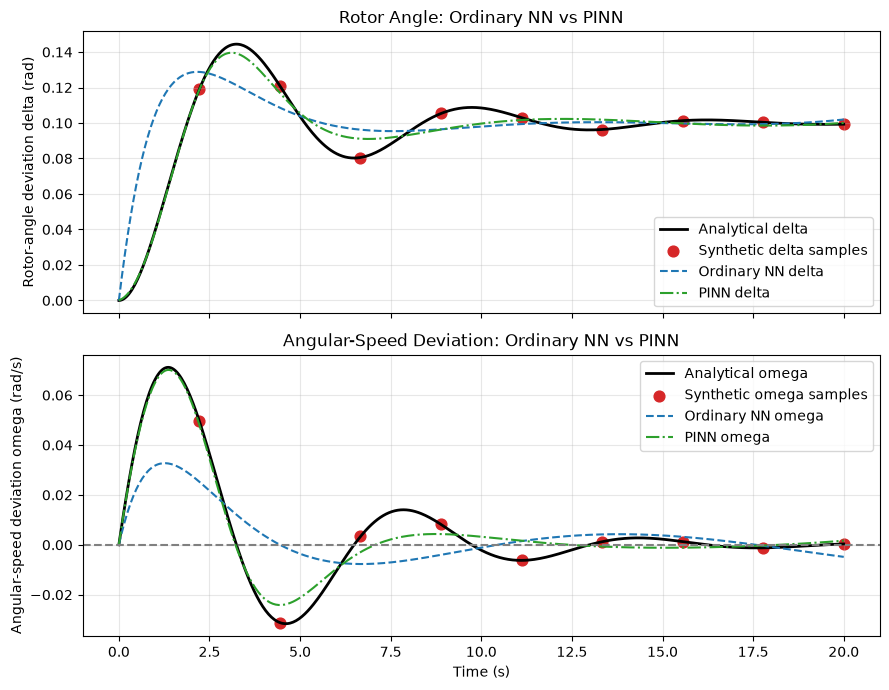

In [10]:
with torch.no_grad():
    # Evaluate the trained data_model and trained pinn_model on the full time grid.
    data_only_pred = data_model(t_eval)
    data_only_delta_pred = data_only_pred[:, 0:1]
    data_only_omega_pred = data_only_pred[:, 1:2]

    pinn_pred = pinn_model(t_eval)
    pinn_delta_pred = pinn_pred[:, 0:1]
    pinn_omega_pred = pinn_pred[:, 1:2]

    data_only_delta_mae = torch.mean(torch.abs(data_only_delta_pred - delta_exact)).item()
    data_only_omega_mae = torch.mean(torch.abs(data_only_omega_pred - omega_exact)).item()
    pinn_delta_mae = torch.mean(torch.abs(pinn_delta_pred - delta_exact)).item()
    pinn_omega_mae = torch.mean(torch.abs(pinn_omega_pred - omega_exact)).item()
    data_only_delta_rmse = torch.sqrt(torch.mean((data_only_delta_pred - delta_exact) ** 2)).item()
    data_only_omega_rmse = torch.sqrt(torch.mean((data_only_omega_pred - omega_exact) ** 2)).item()
    pinn_delta_rmse = torch.sqrt(torch.mean((pinn_delta_pred - delta_exact) ** 2)).item()
    pinn_omega_rmse = torch.sqrt(torch.mean((pinn_omega_pred - omega_exact) ** 2)).item()

# Evaluate physics on an independent midpoint grid rather than reusing training collocation points.
residual_eval_np = ((np.arange(1000, dtype=np.float32) + 0.5) * (T_END / 1000.0)).reshape(-1, 1)
t_residual_eval = torch.tensor(residual_eval_np, dtype=torch.float32, device=device)
pinn_eval_r_delta, pinn_eval_r_omega = physics_residual(
    pinn_model, t_residual_eval, M, D, Ks, delta_p
)
pinn_r_delta_mae = torch.mean(torch.abs(pinn_eval_r_delta)).item()
pinn_r_omega_mae = torch.mean(torch.abs(pinn_eval_r_omega)).item()
pinn_r_delta_max = torch.max(torch.abs(pinn_eval_r_delta)).item()
pinn_r_omega_max = torch.max(torch.abs(pinn_eval_r_omega)).item()

print(f"Ordinary NN delta MAE:  {data_only_delta_mae:.6f}")
print(f"Ordinary NN omega MAE:  {data_only_omega_mae:.6f}")
print(f"PINN delta MAE:         {pinn_delta_mae:.6f}")
print(f"PINN omega MAE:         {pinn_omega_mae:.6f}")
print(f"Ordinary NN delta RMSE: {data_only_delta_rmse:.6f}")
print(f"Ordinary NN omega RMSE: {data_only_omega_rmse:.6f}")
print(f"PINN delta RMSE:        {pinn_delta_rmse:.6f}")
print(f"PINN omega RMSE:        {pinn_omega_rmse:.6f}")
print(f"PINN r_delta MAE/max on independent grid: {pinn_r_delta_mae:.6e} / {pinn_r_delta_max:.6e} rad/s")
print(f"PINN r_omega MAE/max on independent grid: {pinn_r_omega_mae:.6e} / {pinn_r_omega_max:.6e} pu")

# Learned metrics can move slightly across PyTorch/BLAS versions. Non-finite values are
# genuine execution failures; finite values above the teaching targets produce a warning
# instead of making Colab's Run all fail for a version-dependent optimizer trajectory.
metric_values = {
    "PINN delta MAE": pinn_delta_mae,
    "PINN omega MAE": pinn_omega_mae,
    "PINN r_delta MAE": pinn_r_delta_mae,
    "PINN r_omega MAE": pinn_r_omega_mae,
}
if not np.all(np.isfinite(list(metric_values.values()))):
    raise RuntimeError(f"Training produced non-finite metrics: {metric_values}")

quality_targets = {
    "PINN delta MAE": 0.006,
    "PINN omega MAE": 0.006,
    "PINN r_delta MAE": 0.010,
    "PINN r_omega MAE": 0.010,
}
missed_targets = {
    name: (metric_values[name], target)
    for name, target in quality_targets.items()
    if metric_values[name] >= target
}
if missed_targets:
    warnings.warn(
        "Training completed, but this runtime missed one or more fixed-seed teaching "
        f"targets (observed, target): {missed_targets}. Small differences can arise "
        "across PyTorch and BLAS versions.",
        RuntimeWarning,
    )
else:
    print("Fixed-seed quality targets passed against the analytical solution and an independent residual grid.")
print("The ordinary-NN comparison is empirical for this run, not a universal PINN guarantee.")

fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
axes[0].plot(t_eval_np, delta_exact_np, color="black", linewidth=2, label="Analytical delta")
axes[0].scatter(measurement_times, measurement_delta, color="tab:red", s=60, label="Synthetic delta samples")
axes[0].plot(t_eval_np, data_only_delta_pred.cpu().numpy(), linestyle="--", color="tab:blue", label="Ordinary NN delta")
axes[0].plot(t_eval_np, pinn_delta_pred.cpu().numpy(), linestyle="-.", color="tab:green", label="PINN delta")
axes[0].set_ylabel("Rotor-angle deviation delta (rad)")
axes[0].set_title("Rotor Angle: Ordinary NN vs PINN")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(t_eval_np, omega_exact_np, color="black", linewidth=2, label="Analytical omega")
axes[1].scatter(measurement_times, measurement_omega, color="tab:red", s=60, label="Synthetic omega samples")
axes[1].plot(t_eval_np, data_only_omega_pred.cpu().numpy(), linestyle="--", color="tab:blue", label="Ordinary NN omega")
axes[1].plot(t_eval_np, pinn_omega_pred.cpu().numpy(), linestyle="-.", color="tab:green", label="PINN omega")
axes[1].axhline(0.0, linestyle="--", color="gray")
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Angular-speed deviation omega (rad/s)")
axes[1].set_title("Angular-Speed Deviation: Ordinary NN vs PINN")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()


In [11]:
print("Key takeaway:")
print("In this fixed-seed example, the PINN fits rotor-angle and angular-speed trajectories while reducing normalized swing-equation residuals over the tested time domain.")

Key takeaway:
In this fixed-seed example, the PINN fits rotor-angle and angular-speed trajectories while reducing normalized swing-equation residuals over the tested time domain.


## References

The physical model and terminology in this notebook are based on standard power-system stability references rather than invented equations:

1. P. Kundur, *Power System Stability and Control*. New York, NY, USA: McGraw-Hill, 1994.
2. P. Kundur et al., "Definition and Classification of Power System Stability IEEE/CIGRE Joint Task Force on Stability Terms and Definitions," *IEEE Transactions on Power Systems*, vol. 19, no. 3, pp. 1387-1401, Aug. 2004, doi: [10.1109/TPWRS.2004.825981](https://doi.org/10.1109/TPWRS.2004.825981).
3. M. Bakhtvar, E. Vittal, K. Zheng, and A. Keane, "Synchronizing Torque Impacts on Rotor Speed in Power Systems," *IEEE Transactions on Power Systems*, vol. 32, no. 3, pp. 1927-1935, May 2017, doi: [10.1109/TPWRS.2016.2600478](https://doi.org/10.1109/TPWRS.2016.2600478).
4. M. Raissi, P. Perdikaris, and G. E. Karniadakis, "Physics-informed neural networks: A deep learning framework for solving forward and inverse problems involving nonlinear partial differential equations," *Journal of Computational Physics*, vol. 378, pp. 686-707, Feb. 2019, doi: [10.1016/j.jcp.2018.10.045](https://doi.org/10.1016/j.jcp.2018.10.045).
5. G. S. Misyris, A. Venzke, and S. Chatzivasileiadis, "Physics-Informed Neural Networks for Power Systems," *2020 IEEE Power & Energy Society General Meeting (PESGM)*, pp. 1-5, 2020, doi: [10.1109/PESGM41954.2020.9282004](https://doi.org/10.1109/PESGM41954.2020.9282004); preprint: [arXiv:1911.03737](https://arxiv.org/abs/1911.03737).
